In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
from tensorflow import keras
from keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization

In [ ]:
import os
import cv2
import glob as gb
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
print("Loaded all libraries")

Loaded all libraries


In [ ]:
path = '/content/drive/MyDrive/soybean'

Found 5513 images belonging to 2 classes.


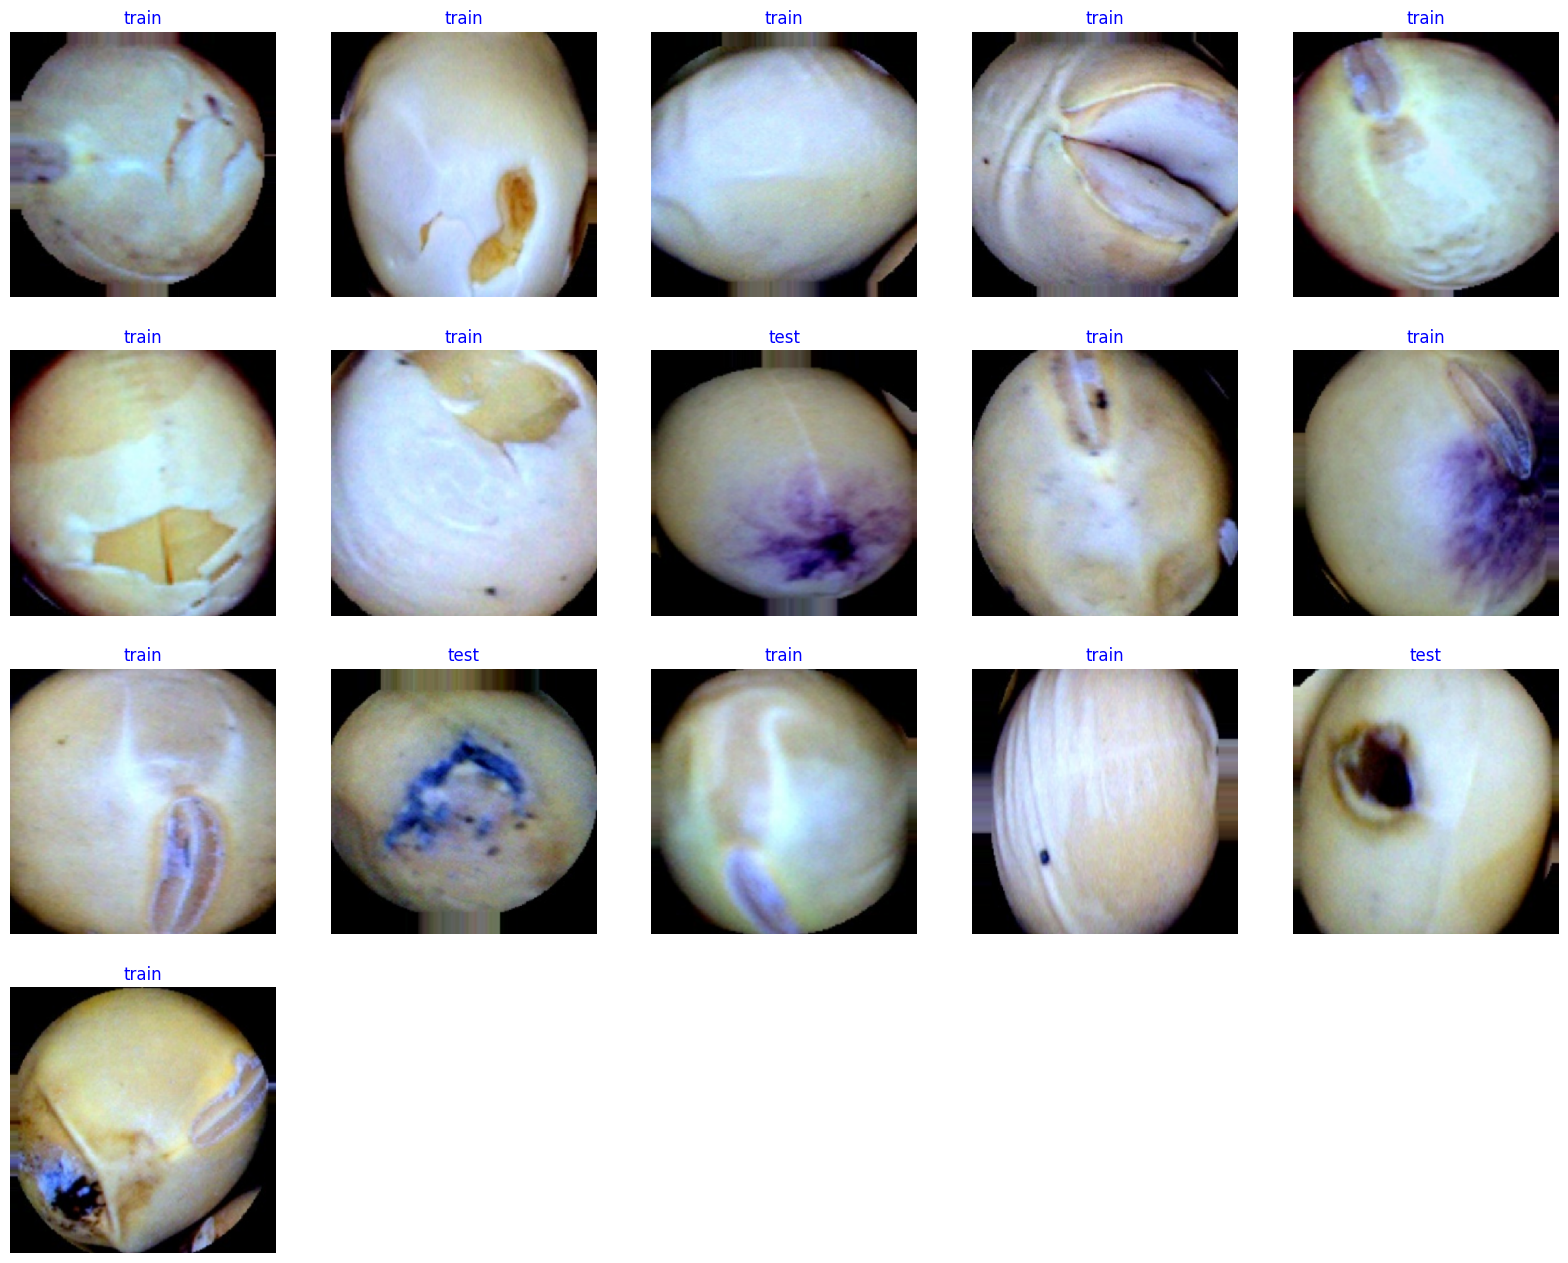

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator # Changed import statement

train_gen = ImageDataGenerator(
    rescale=1. / 255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)
train_batch = train_gen.flow_from_directory(
    directory=path,
    target_size=(351,351),
    batch_size=16,
)
g_dict = train_batch.class_indices      # defines dictionary {'class': index}
classes = list(g_dict.keys())       # defines list of dictionary's kays (classes), classes names : string
images, labels = next(train_batch)      # get a batch size samples from the generator

# calculate number of displayed samples
length = len(labels)        # length of batch size
sample = min(length, 30)    # check if sample less than 25 images

plt.figure(figsize= (20, 20))

for i in range(sample):
    plt.subplot(5, 5, i + 1)
    image = images[i]      # scales data to range (0 - 255)
    plt.imshow(image)
    index = np.argmax(labels[i])  # get image index
    class_name = classes[index]   # get class of image
    plt.title(class_name, color= 'blue', fontsize= 12)
    plt.axis('off')
plt.show()

In [ ]:
training_data = keras.preprocessing.image_dataset_from_directory(
    path,
    batch_size = 10,
    image_size =(300,300),

    shuffle = True,
    seed =123,
    subset ='training',
    validation_split=0.2
    )
validation_data =keras.preprocessing.image_dataset_from_directory(
    path,
    batch_size = 10,
    image_size =(300,300),

    shuffle = True,
    seed =123,
    validation_split =0.2,
    subset ='validation'

    )

Found 5513 files belonging to 2 classes.
Using 4411 files for training.
Found 5513 files belonging to 2 classes.
Using 1102 files for validation.


In [ ]:
resnet_model = Sequential()

pretrained_model= keras.applications.ResNet50(include_top=False,
                   input_shape=(300,300,3),
                   pooling='avg',classes=5,
                   weights='imagenet')
for layer in pretrained_model.layers:
        layer.trainable=False

resnet_model.add(pretrained_model)
resnet_model.add(Flatten())
resnet_model.add(Dense(512, activation='relu'))
resnet_model.add(Dense(5, activation='softmax'))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
resnet_model.compile(loss='sparse_categorical_crossentropy', optimizer=keras.optimizers.SGD(learning_rate=0.0009), metrics=['accuracy'])

In [ ]:
epochs=25
history = resnet_model.fit(

  training_data,
  validation_data=validation_data,
  epochs=epochs
)

Epoch 1/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 885s 2s/step - accuracy: 0.7790 - loss: 0.6133 - val_accuracy: 0.8240 - val_loss: 0.4908
Epoch 2/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 78s 78ms/step - accuracy: 0.7971 - loss: 0.5086 - val_accuracy: 0.8249 - val_loss: 0.4685
Epoch 3/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 34s 76ms/step - accuracy: 0.7948 - loss: 0.5007 - val_accuracy: 0.8240 - val_loss: 0.4643
Epoch 4/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 41s 77ms/step - accuracy: 0.7958 - loss: 0.4931 - val_accuracy: 0.8230 - val_loss: 0.4758
Epoch 5/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 37s 67ms/step - accuracy: 0.7968 - loss: 0.4865 - val_accuracy: 0.8249 - val_loss: 0.4626
Epoch 6/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 41s 67ms/step - accuracy: 0.7959 - loss: 0.4844 - val_accuracy: 0.8249 - val_loss: 0.4608
Epoch 7/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 46s 78ms/step - accuracy: 0.7972 - loss: 0.4802 - val_accuracy: 0.7278 - val_loss: 0.6018
Epoch 8/25
442/442 ━━━━━━━━━━━━━━━━━━━━ 36s 67ms/step - accuracy: 0.7935 - loss: 0.4847 - v

In [ ]:
test_loss, test_acc = resnet_model.evaluate(validation_data, steps=len(validation_data))  # Use resnet_model and validation_data
print(f'Test Accuracy: {test_acc:.2f}')

111/111 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.8415 - loss: 0.4378
Test Accuracy: 0.82


In [ ]:
# Get predictions from the model for the ENTIRE test set
predictions = resnet_model.predict(validation_data, steps=len(validation_data)) # Use resnet_model instead of model and validation_data

111/111 ━━━━━━━━━━━━━━━━━━━━ 14s 91ms/step


In [ ]:
# Convert predictions to class labels
predicted_classes = np.argmax(predictions, axis=1)

In [ ]:
# Get true labels from the validation_data
# Since you are evaluating on validation_data, extract true labels from it
true_classes = []
for images, labels in validation_data.take(len(validation_data)):  # Iterate through all batches
    true_classes.extend(labels.numpy())  # Extend the list with true labels from the current batch

true_classes = np.array(true_classes)  # Convert to NumPy array

In [ ]:
from sklearn.metrics import classification_report # Make sure you have imported classification_report
import numpy as np
print(classification_report(true_classes, predicted_classes, target_names=list(training_data.class_names)))


              precision    recall  f1-score   support

        test       0.40      0.01      0.02       193
       train       0.83      1.00      0.90       909

    accuracy                           0.82      1102
   macro avg       0.61      0.50      0.46      1102
weighted avg       0.75      0.82      0.75      1102

